**Trabajo Unidad I**

Carrera: Ingeniería Civil Industrial

Asignatura: MACHINE LEARNING | eINGT1029-01

Profesor: Franco Mansilla

Fecha de envío: 09-10-2026

Nombre(s) de estudiante(s):
•	Yorka Castillo
•	Melanie Olguin
•	Ignacio Rivera
•	Paulina Soto


**Introducción**

Tener la capacidad de análisis bases de datos con extensa información para predecir resultados, hoy en día es una herramienta fundamental para las empresas, donde la capacidad de transformar volúmenes masivos de información en decisiones es una ventaja competitiva en el mercado.

Dentro del análisis de datos, existe la recopilación, exploración y limpieza de datos, las cuales son las etapas de consolidación inicial, para luego tener una modelación predictiva avanzada. Aquí se abordará esa transformación, teniendo en cuenta el diseño, entrenamiento, evaluación y selección de los modelos de Machine Learning, y así resolver problemas de clasificación binaria.


En el mercado actual el contar con clasificación binaria ha demostrado predecir casos de uso críticos, desde la detección de fraude en transacciones financieras hasta la clasificación de riesgo crediticio en los usuarios, incluso el predecir el mantenimiento preventivo de maquinarias industriales, dándole un uso fundamental a las herramientas de análisis de datos. Por otro lado, el poder implementar soluciones predictivas ayuda a reducir las pérdidas económicas de insumos, optimizando la asignación de recursos.

En este análisis se buscará implementar un modelo que arrojará información de los posibles casos de sobrevivencia en el accidente del Titanic.





# **Parte 1 Trabajo**

In [ ]:
#1. Carga de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/train.csv')

df.head()

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)

display(df.head())

Dataset cargado correctamente
Dimensiones: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
#2. Información de datos

print("DIMENSIONES")
print(df.shape)

print("\nCOLUMNAS")
print(df.columns.tolist())

print("\nPRIMEROS REGISTROS")
display(df.head())

print("\nINFORMACIÓN DEL DATASET")
df.info()

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe())


DIMENSIONES
(891, 12)

COLUMNAS
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

PRIMEROS REGISTROS


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



INFORMACIÓN DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

ESTADÍSTICAS DESCRIPTIVAS


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
display(df.describe(include="object"))

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [ ]:
#3. Variable Objetiva

print("Cantidad por clase:")
print(df["Survived"].value_counts())

print("\nPorcentaje por clase:")
print(df["Survived"].value_counts(normalize=True) * 100)

Cantidad por clase:
Survived
0    549
1    342
Name: count, dtype: int64

Porcentaje por clase:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


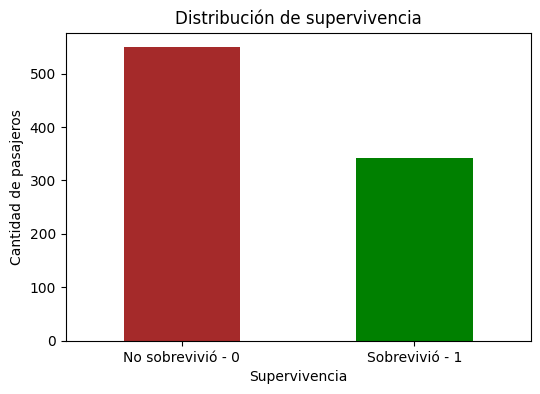

In [ ]:
plt.figure(figsize=(6, 4))

df["Survived"].value_counts().sort_index().plot(
    kind="bar",
    color=["brown", "green"]
)

plt.title("Distribución de supervivencia")
plt.xlabel("Supervivencia")
plt.ylabel("Cantidad de pasajeros")
plt.xticks(
    ticks=[0, 1],
    labels=["No sobrevivió - 0", "Sobrevivió - 1"],
    rotation=0
)

plt.show()

In [ ]:
#4. Supervivencia según sexo

tabla_sexo = pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
) * 100

display(tabla_sexo)

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


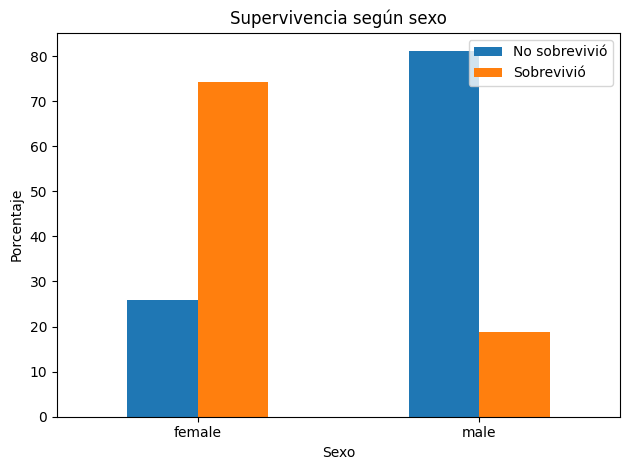

In [ ]:
tabla_sexo.plot(kind="bar")

plt.title("Supervivencia según sexo")
plt.xlabel("Sexo")
plt.ylabel("Porcentaje")
plt.xticks(rotation=0)
plt.legend(["No sobrevivió", "Sobrevivió"])
plt.tight_layout()
plt.show()

In [ ]:
#5. Supervivencia según tipo de clase

tabla_clase = pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
) * 100

display(tabla_clase)

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


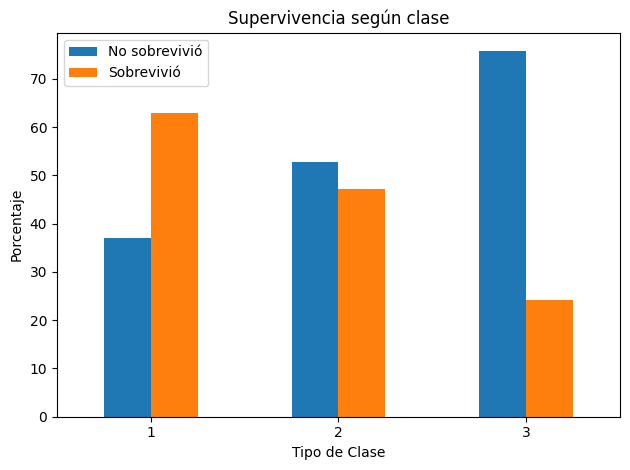

In [ ]:
tabla_clase.plot(kind="bar")

plt.title("Supervivencia según clase")
plt.xlabel("Tipo de Clase")
plt.ylabel("Porcentaje")
plt.xticks(rotation=0)
plt.legend(["No sobrevivió", "Sobrevivió"])
plt.tight_layout()
plt.show()

In [ ]:
#6. Identificar valores faltantes

missing = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing.sort_values(
    by="Cantidad",
    ascending=False
))

,Cantidad,Porcentaje
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


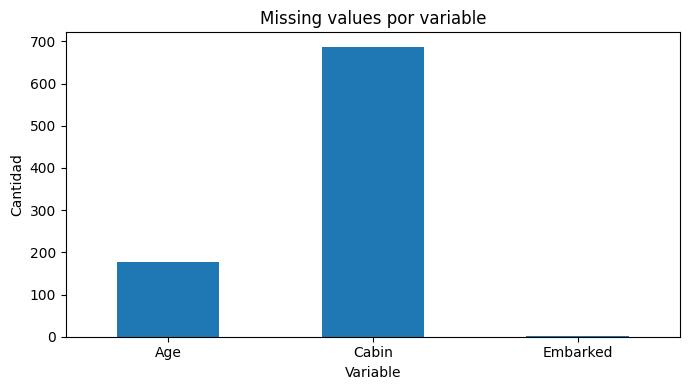

In [ ]:
missing_plot = missing[missing["Cantidad"] > 0]

plt.figure(figsize=(7, 4))

missing_plot["Cantidad"].plot(kind="bar")

plt.title("Missing values por variable")
plt.xlabel("Variable")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
#7. Limpiar codigos - Revisar duplicados

print("Filas duplicadas:")
print(df.duplicated().sum())

df = df.drop_duplicates()

Filas duplicadas:
0


In [ ]:
#8. Explorar Edad

print(df["Age"].describe())

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64


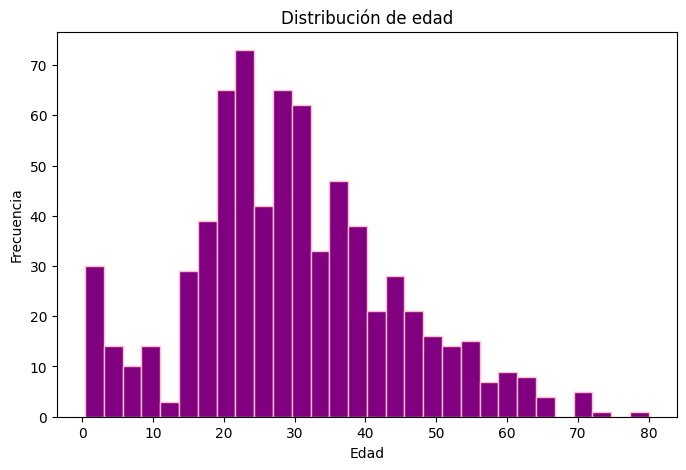

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Age"].dropna(),
    bins=30,
    color="purple",
    edgecolor="pink",
    linewidth=1
)

plt.title("Distribución de edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

In [ ]:
#9. Detectar outliers mediante IQR

def detectar_outliers_iqr(data, columna):

    Q1 = data[columna].quantile(0.25)
    Q3 = data[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = data[
        (data[columna] < limite_inferior) |
        (data[columna] > limite_superior)
    ]

    print("Variable:", columna)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Límite inferior:", limite_inferior)
    print("Límite superior:", limite_superior)
    print("Cantidad de outliers:", len(outliers))

    return outliers

In [ ]:
#Variable Edad

outliers_age = detectar_outliers_iqr(
    df,
    "Age"
)

Variable: Age
Q1: 20.125
Q3: 38.0
IQR: 17.875
Límite inferior: -6.6875
Límite superior: 64.8125
Cantidad de outliers: 11


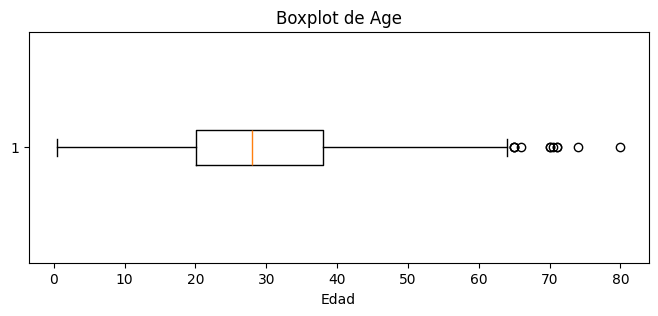

In [ ]:
plt.figure(figsize=(8, 3))

plt.boxplot(
    df["Age"].dropna(),
    vert=False
)

plt.title("Boxplot de Age")
plt.xlabel("Edad")
plt.show()

In [ ]:
#Variable Tarifa

outliers_fare = detectar_outliers_iqr(
    df,
    "Fare"
)

Variable: Fare
Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Límite inferior: -26.724
Límite superior: 65.6344
Cantidad de outliers: 116


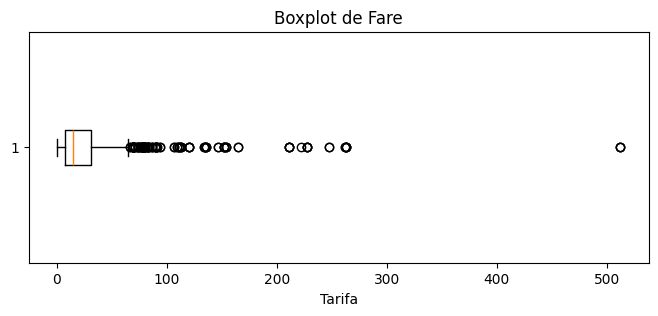

In [ ]:
plt.figure(figsize=(8, 3))

plt.boxplot(
    df["Fare"].dropna(),
    vert=False
)

plt.title("Boxplot de Fare")
plt.xlabel("Tarifa")
plt.show()

In [ ]:
df_clean = df.copy()

In [ ]:
#Mediana de Edad

mediana_age = df_clean["Age"].median()

print("Mediana Age:", mediana_age)

df_clean["Age"] = (
    df_clean["Age"]
    .fillna(mediana_age)
)

Mediana Age: 28.0


In [ ]:
# Moda Embarque

moda_embarked = df_clean["Embarked"].mode()[0]

print("Moda Embarked:", moda_embarked)

df_clean["Embarked"] = (
    df_clean["Embarked"]
    .fillna(moda_embarked)
)

# Comprobar que ya no quedan valores faltantes
print("Missing values en Embarked:", df_clean["Embarked"].isnull().sum())

Moda Embarked: S
Missing values en Embarked: 0


In [ ]:
df_clean = df_clean.drop(
    columns=["Cabin"]
)

In [ ]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [ ]:
#13. Tratamiento de Fare

df_clean["Fare_log"] = np.log1p(
    df_clean["Fare"]
)

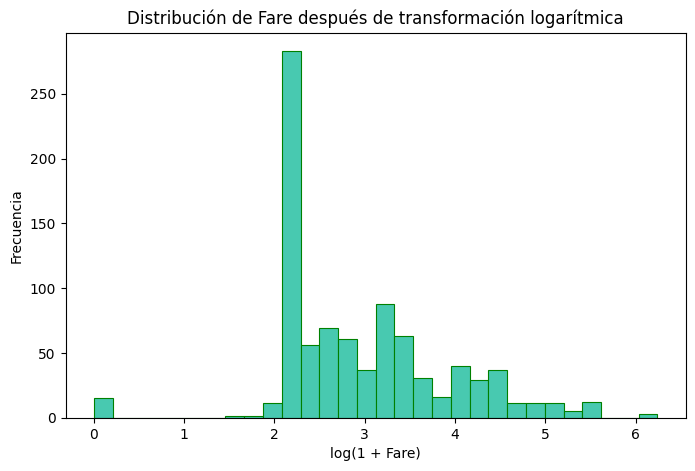

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["Fare_log"],
    bins=30,
    color="#48C9B0",
    edgecolor="green",
    linewidth=0.8
)

plt.title("Distribución de Fare después de transformación logarítmica")
plt.xlabel("log(1 + Fare)")
plt.ylabel("Frecuencia")

plt.show()

In [ ]:
#14. Eliminar variables que no utilizaremos

df_model = df_clean.drop(
    columns=[
        "PassengerId",
        "Name",
        "Ticket",
        "Fare"
    ]
)

display(df_model.head())

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,Fare_log
0,0,3,male,22.0,1,0,S,2.110213
1,1,1,female,38.0,1,0,C,4.280593
2,1,3,female,26.0,0,0,S,2.188856
3,1,1,female,35.0,1,0,S,3.990834
4,0,3,male,35.0,0,0,S,2.202765


In [ ]:
#15. Codificación de variables categóricas (convertir variables Sex y Embarked en números)

df_model = pd.get_dummies(
    df_model,
    columns=[
        "Sex",
        "Embarked"
    ],
    drop_first=True,
    dtype=int
)

display(df_model.head())

,Survived,Pclass,Age,SibSp,Parch,Fare_log,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,2.110213,1,0,1
1,1,1,38.0,1,0,4.280593,0,0,0
2,1,3,26.0,0,0,2.188856,0,0,1
3,1,1,35.0,1,0,3.990834,0,0,1
4,0,3,35.0,0,0,2.202765,1,0,1


In [ ]:
#16. Separar X e y

X = df_model.drop(
    columns=["Survived"]
)

y = df_model["Survived"]

print("Variables predictoras:")
print(X.columns)

print("\nVariable objetivo:")
print(y.name)

Variables predictoras:
Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare_log', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='object')

Variable objetivo:
Survived


In [ ]:
#17. Método 1: Hold-Out aleatorio

from sklearn.model_selection import train_test_split

X_train_random, X_temp_random, y_train_random, y_temp_random = (
    train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42
    )
)

X_val_random, X_test_random, y_val_random, y_test_random = (
    train_test_split(
        X_temp_random,
        y_temp_random,
        test_size=0.50,
        random_state=42
    )
)

print("TRAIN:", len(X_train_random))
print("VALIDATION:", len(X_val_random))
print("TEST:", len(X_test_random))

TRAIN: 623
VALIDATION: 134
TEST: 134


In [ ]:
#18. Método 2: Hold-Out estratificado

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (623, 8)
Validation: (134, 8)
Test: (134, 8)


In [ ]:
#19. Comprobar la estratificación

def mostrar_distribucion(nombre, y_data):

    print("\n", nombre)

    print(
        y_data
        .value_counts(normalize=True)
        .sort_index()
        .round(3)
    )

mostrar_distribucion(
    "Dataset completo",
    y
)

mostrar_distribucion(
    "Train",
    y_train
)

mostrar_distribucion(
    "Validation",
    y_val
)

mostrar_distribucion(
    "Test",
    y_test
)


 Dataset completo
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

 Train
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

 Validation
Survived
0    0.612
1    0.388
Name: proportion, dtype: float64

 Test
Survived
0    0.619
1    0.381
Name: proportion, dtype: float64


In [ ]:
#20. Método 3: Stratified K-Fold

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_index, val_index) in enumerate(
    skf.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_index]
    X_val_fold = X.iloc[val_index]

    y_train_fold = y.iloc[train_index]
    y_val_fold = y.iloc[val_index]

    print(
        f"Fold {fold}: "
        f"Train = {len(train_index)}, "
        f"Validation = {len(val_index)}"
    )

Fold 1: Train = 712, Validation = 179
Fold 2: Train = 713, Validation = 178
Fold 3: Train = 713, Validation = 178
Fold 4: Train = 713, Validation = 178
Fold 5: Train = 713, Validation = 178


In [ ]:
#21. Tabla comparativa de los tres métodos

comparacion = pd.DataFrame({
    "Método": [
        "Hold-Out aleatorio",
        "Hold-Out estratificado",
        "Stratified K-Fold"
    ],

    "Mantiene proporción clases": [
        "No necesariamente",
        "Sí",
        "Sí"
    ],

    "Costo computacional": [
        "Bajo",
        "Bajo",
        "Mayor"
    ],

    "Ventaja principal": [
        "Simple y rápido",
        "Muestras representativas",
        "Evaluación más robusta"
    ],

    "Desventaja principal": [
        "Puede desbalancear las clases",
        "Depende de una sola división",
        "Mayor tiempo de procesamiento"
    ]
})

display(comparacion)

,Método,Mantiene proporción clases,Costo computacional,Ventaja principal,Desventaja principal
0,Hold-Out aleatorio,No necesariamente,Bajo,Simple y rápido,Puede desbalancear las clases
1,Hold-Out estratificado,Sí,Bajo,Muestras representativas,Depende de una sola división
2,Stratified K-Fold,Sí,Mayor,Evaluación más robusta,Mayor tiempo de procesamiento


In [ ]:
#22. Pipeline reproducible

def limpiar_titanic(data):

    df_clean = data.copy()

    # Eliminar duplicados
    df_clean = df_clean.drop_duplicates()

    # Crear variable de disponibilidad de cabina
    df_clean["HasCabin"] = (
        df_clean["Cabin"]
        .notna()
        .astype(int)
    )

    # Imputación de Age
    df_clean["Age"] = (
        df_clean["Age"]
        .fillna(
            df_clean["Age"].median()
        )
    )

    # Imputación de Embarked
    df_clean["Embarked"] = (
        df_clean["Embarked"]
        .fillna(
            df_clean["Embarked"].mode()[0]
        )
    )

    # Transformar Fare
    df_clean["Fare_log"] = np.log1p(
        df_clean["Fare"]
    )

    # Eliminar variables no utilizadas
    df_clean = df_clean.drop(
        columns=[
            "PassengerId",
            "Name",
            "Ticket",
            "Cabin",
            "Fare"
        ]
    )

    # One-Hot Encoding
    df_clean = pd.get_dummies(
        df_clean,
        columns=[
            "Sex",
            "Embarked"
        ],
        drop_first=True,
        dtype=int
    )

    return df_clean

In [ ]:
datos_originales = pd.read_csv(
    "/content/drive/MyDrive/train.csv"
)

datos_limpios = limpiar_titanic(
    datos_originales
)

display(datos_limpios.head())

print("\nMissing values:")
print(datos_limpios.isnull().sum())

,Survived,Pclass,Age,SibSp,Parch,HasCabin,Fare_log,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,0,2.110213,1,0,1
1,1,1,38.0,1,0,1,4.280593,0,0,0
2,1,3,26.0,0,0,0,2.188856,0,0,1
3,1,1,35.0,1,0,1,3.990834,0,0,1
4,0,3,35.0,0,0,0,2.202765,1,0,1



Missing values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
HasCabin      0
Fare_log      0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64


In [ ]:
#23. Función split

def split_estratificado(
    data,
    target="Survived",
    random_state=42
):

    X = data.drop(
        columns=[target]
    )

    y = data[target]

    X_train, X_temp, y_train, y_temp = (
        train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=random_state,
            stratify=y
        )
    )

    X_val, X_test, y_val, y_test = (
        train_test_split(
            X_temp,
            y_temp,
            test_size=0.50,
            random_state=random_state,
            stratify=y_temp
        )
    )

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

In [ ]:
(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test
) = split_estratificado(
    datos_limpios
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (623, 9)
Validation: (134, 9)
Test: (134, 9)


In [ ]:
# PIPELINE FINAL TITANIC

from sklearn.model_selection import train_test_split


# 1. Carga
df = pd.read_csv(
    "/content/drive/MyDrive/train.csv"
)


# 2. Limpieza
df_clean = limpiar_titanic(df)


# 3. Calidad final
print("Missing values:")
print(df_clean.isnull().sum())


# 4. Separación
(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test
) = split_estratificado(
    df_clean
)


# 5. Resultados
print("\n---------------------------")
print("RESULTADO DEL PIPELINE")
print("---------------------------")

print(
    "Dataset original:",
    df.shape
)

print(
    "Dataset procesado:",
    df_clean.shape
)

print(
    "Entrenamiento:",
    X_train.shape
)

print(
    "Validación:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)

print(
    "Duplicados en dataset original:",
    df.duplicated().sum()
)

print(
    "Filas idénticas después de seleccionar variables:",
    df_clean.duplicated().sum()
)

Missing values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
HasCabin      0
Fare_log      0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

---------------------------
RESULTADO DEL PIPELINE
---------------------------
Dataset original: (891, 12)
Dataset procesado: (891, 10)
Entrenamiento: (623, 9)
Validación: (134, 9)
Test: (134, 9)
Duplicados en dataset original: 0
Filas idénticas después de seleccionar variables: 111


Método seleccionado

Se selecciona Hold-Out estratificado para realizar la separación principal en entrenamiento, validación y test.

Esto se debe a que el problema corresponde a clasificación binaria y la variable Survived tiene una distribución aproximada de:

61,6 % clase 0.
38,4 % clase 1.

Al estratificar, se mantiene una proporción semejante en las tres muestras.

La distribución utilizada será:

70 % entrenamiento.
15 % validación.
15 % test.

Stratified K-Fold también es una alternativa muy apropiada para evaluar modelos durante la fase de experimentación, pero para cumplir específicamente con la necesidad de disponer de tres conjuntos independientes, Hold-Out estratificado resulta simple y apropiado.

# **Parte 2 Trabajo**

**TRABAJO UNIDAD II - MODELAMIENTO Y EVALUACIÓN**


In [ ]:
# Modelos
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression   # Modelo de Penalización (ElasticNet / Lasso / Ridge)
from sklearn.ensemble import RandomForestClassifier   # Random Forest
from xgboost import XGBClassifier                     # XGBoost
from sklearn.neural_network import MLPClassifier      # Red Neuronal Simple (Perceptrón Multicapa)

# Métricas y Optimización
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay
)
from sklearn.model_selection import GridSearchCV

# ESCALADO DE DATOS (Modelos Lineales/Penalizados y Redes Neuronales)
# Ajustamos el escalador únicamente con los datos de entrenamiento para evitar Data Leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# 2. FUNCIÓN DE EVALUACIÓN DE MÉTRICAS (TRAIN Y VALIDACIÓN)

def calcular_ks(y_true, y_proba):
    """Calcula el estadístico Kolmogorov-Smirnov (KS)."""
    scores_pos = y_proba[y_true == 1]
    scores_neg = y_proba[y_true == 0]
    ks_stat, _ = ks_2samp(scores_pos, scores_neg)
    return ks_stat

def evaluar_modelo(modelo, X_tr, y_tr, X_v, y_v, nombre_modelo):
    """Calcula y consolida las métricas de desempeño para Train y Validation."""
    # Predicciones Train
    y_tr_pred = modelo.predict(X_tr)
    y_tr_proba = modelo.predict_proba(X_tr)[:, 1]

    # Predicciones Validation
    y_v_pred = modelo.predict(X_v)
    y_v_proba = modelo.predict_proba(X_v)[:, 1]

    # Métricas Train
    acc_tr = accuracy_score(y_tr, y_tr_pred)
    prec_tr = precision_score(y_tr, y_tr_pred, zero_division=0)
    rec_tr = recall_score(y_tr, y_tr_pred, zero_division=0)
    f1_tr = f1_score(y_tr, y_tr_pred, zero_division=0)
    auc_tr = roc_auc_score(y_tr, y_tr_proba)
    ks_tr = calcular_ks(y_tr.values, y_tr_proba)

    # Métricas Validation
    acc_v = accuracy_score(y_v, y_v_pred)
    prec_v = precision_score(y_v, y_v_pred, zero_division=0)
    rec_v = recall_score(y_v, y_v_pred, zero_division=0)
    f1_v = f1_score(y_v, y_v_pred, zero_division=0)
    auc_v = roc_auc_score(y_v, y_v_proba)
    ks_v = calcular_ks(y_v.values, y_v_proba)

    df_res = pd.DataFrame({
        "Modelo": [nombre_modelo, nombre_modelo],
        "Set": ["Train", "Validation"],
        "Accuracy": [acc_tr, acc_v],
        "Precision": [prec_tr, prec_v],
        "Recall": [rec_tr, rec_v],
        "F1-Score": [f1_tr, f1_v],
        "AUC": [auc_tr, auc_v],
        "KS": [ks_tr, ks_v]
    })
    return df_res

In [ ]:
# 1) ENTRENAMIENTO DE LOS 4 MODELOS BASE

# 1.1 Modelo de Penalización: ElasticNet (combina L1/Lasso y L2/Ridge)

model_elastic = LogisticRegression(
    penalty='elasticnet',
    l1_ratio=0.5,
    C=0.5,
    solver='saga',
    max_iter=2000,
    random_state=42
)
model_elastic.fit(X_train_scaled, y_train)

# 1.2 Random Forest
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
model_rf.fit(X_train, y_train)

# 1.3 XGBoost
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    eval_metric='logloss',
    random_state=42
)
model_xgb.fit(X_train, y_train)

# 1.4 Red Neuronal Simple (Multi-Layer Perceptron)
# 1 capa oculta de 16 neuronas con regularización L2 (alpha)
model_nn = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='adam',
    alpha=0.01,
    max_iter=1000,
    random_state=42
)
model_nn.fit(X_train_scaled, y_train)

print("Los modelos han sido entrenados con éxito")

Los modelos han sido entrenados con éxito


In [ ]:
# PUNTO 2: CÁLCULO Y COMPARACIÓN DE MÉTRICAS

res_elastic = evaluar_modelo(model_elastic, X_train_scaled, y_train, X_val_scaled, y_val, "ElasticNet")
res_rf = evaluar_modelo(model_rf, X_train, y_train, X_val, y_val, "Random Forest")
res_xgb = evaluar_modelo(model_xgb, X_train, y_train, X_val, y_val, "XGBoost")
res_nn = evaluar_modelo(model_nn, X_train_scaled, y_train, X_val_scaled, y_val, "Red Neuronal")

tabla_metricas = pd.concat([res_elastic, res_rf, res_xgb, res_nn], ignore_index=True)
display(tabla_metricas.round(4))

,Modelo,Set,Accuracy,Precision,Recall,F1-Score,AUC,KS
0,ElasticNet,Train,0.8026,0.7500,0.7280,0.7389,0.8692,0.5873
1,ElasticNet,Validation,0.8582,0.8113,0.8269,0.8190,0.8954,0.7312
2,Random Forest,Train,0.8732,0.8810,0.7741,0.8241,0.9235,0.7330
3,Random Forest,Validation,0.8433,0.8605,0.7115,0.7789,0.9080,0.7209
4,XGBoost,Train,0.8636,0.9010,0.7238,0.8028,0.9253,0.7043
5,XGBoost,Validation,0.8582,0.9024,0.7115,0.7957,0.9001,0.7083
6,Red Neuronal,Train,0.8395,0.8601,0.6946,0.7685,0.8980,0.6669
7,Red Neuronal,Validation,0.8507,0.8636,0.7308,0.7917,0.9146,0.7294


**ElasticNet**: Logró un Accuracy de 0.8582 y Recall de 0.8269 en validación, sin embargo un KS en train 0.5873, lo que muestra una menor capacidad de separación.  

**XGBoost**: Tuvo la precisión más alta en validación con 0.9024, pero un Recall  un poco mas bajo de 0.7115.  

**Red Neuronal** (MLP): Obtuvo un AUC mas elevado en validación de 0.9146.  

**Random Forest Tuned**: Es el mas estable, ya que alcanzo un AUC de 0.9123 y un F1-Score de 0.7789 en validación.  

In [ ]:
# PUNTO 3: OPTIMIZACIÓN DE HIPERPARÁMETROS

# Espacio de búsqueda de hiperparámetros
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

# Configuración del GridSearch optimizando para ROC-AUC
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("\n--- RESULTADOS DE LA OPTIMIZACIÓN ---")
print("Mejores Hiperparámetros:", grid_rf.best_params_)
print(f"Mejor ROC-AUC en CV (Train): {grid_rf.best_score_:.4f}")

# Evaluación del modelo optimizado
mejor_rf = grid_rf.best_estimator_
res_mejor_rf = evaluar_modelo(mejor_rf, X_train, y_train, X_val, y_val, "Random Forest (Tuned)")
display(res_mejor_rf.round(4))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

--- RESULTADOS DE LA OPTIMIZACIÓN ---
Mejores Hiperparámetros: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Mejor ROC-AUC en CV (Train): 0.8765


,Modelo,Set,Accuracy,Precision,Recall,F1-Score,AUC,KS
0,Random Forest (Tuned),Train,0.8668,0.8824,0.7531,0.8126,0.9218,0.7259
1,Random Forest (Tuned),Validation,0.8433,0.8605,0.7115,0.7789,0.9123,0.7139


REPORTE DE CLASIFICACIÓN EN TEST 
                   precision    recall  f1-score   support

    Fallecido (0)       0.80      0.86      0.83        83
Sobreviviente (1)       0.73      0.65      0.69        51

         accuracy                           0.78       134
        macro avg       0.77      0.75      0.76       134
     weighted avg       0.77      0.78      0.77       134



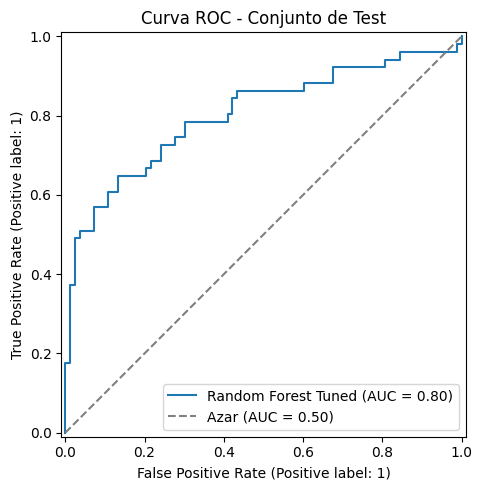

In [ ]:
# PUNTO 4: EVALUACIÓN EN TEST DEL MODELO FINAL Y CURVA ROC

y_test_pred = mejor_rf.predict(X_test)
y_test_proba = mejor_rf.predict_proba(X_test)[:, 1]

print("REPORTE DE CLASIFICACIÓN EN TEST ")
print(classification_report(y_test, y_test_pred, target_names=["Fallecido (0)", "Sobreviviente (1)"]))

# Gráfico de la Curva ROC
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(mejor_rf, X_test, y_test, ax=ax, name="Random Forest Tuned")
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar (AUC = 0.50)')
ax.set_title("Curva ROC - Conjunto de Test")
ax.legend()
plt.tight_layout()
plt.show()

**Modelo Final**

El modelo a elegir es el Random Forest, esto se debe a que al comparar los distintos modelos, en validación tuvo una precisión de 0,8605 y un F1-Score de 0,7789. Al comparar el conjunto de entrenamiento (Accuracy 0.8668, AUC 0.9218) con validación (Accuracy 0.8433, AUC 0.9123), donde existe poca brecha entre ellos.

Al analizar el conjunto de prueba, el modelo mantuvo un desempeño de Accuracy de 0.78 y un AUC de 0.84.

A diferencia de los modelos lineales, Random Forest logró captar interacciones claves observadas en el EDA, sin requerir supuestos de linealidad ni transformaciones matemáticas complejas.



**Interpretación de la Evaluación Final**

El test se realizo sobre 134 casos de prueba, obteniendo:

**Clase 0 (No sobrevivió)**: Precisión de 0.80 y Recall de 0.86 (F1 = 0.83). El modelo clasifica adecuadamente a la mayoría de quienes no lograron sobrevivir.  

**Clase 1 (Sobreviviente)**: Precisión de 0.73 y Recall de 0.65 (F1 = 0.69). De las personas que predijo como sobrevivientes, el 73% efectivamente sobrevivió, cabe mencionar que se omite alrededor de un 35% de sobrevivientes reales, como falsos negativos.  

**Curva ROC**: Un AUC de 0.84 logra confirmar que el modelo puede predecir significativamente a una clasificación aleatoria (AUC = 0.50), demostrando que la solución es reproducible con nuevos datos.

# **Parte 3 Trabajo**

**TRABAJO UNIDAD III - Algoritmos no-supervisados**


In [ ]:
# 1. Librerías y configuración
from pathlib import Path
import sys
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn import __version__ as sklearn_version
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    pairwise_distances,
)
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn_version)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)

Python: 3.13.15
scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.1.3


In [ ]:
# 2. Cargando train.csv desde Google Drive

from google.colab import drive
from pathlib import Path
import pandas as pd

# Montar Google Drive
drive.mount('/content/drive')

# Ruta del archivo en la carpeta principal de Google Drive (Mi unidad)
DATA_PATH = Path('/content/drive/MyDrive/train.csv')

# Verificar que el archivo exista
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo en: {DATA_PATH}"
    )

# Cargar dataset
df_raw = pd.read_csv(DATA_PATH)

print("Archivo cargado:", DATA_PATH)
print("Dimensiones originales:", df_raw.shape)

display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivo cargado: /content/drive/MyDrive/train.csv
Dimensiones originales: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# 3. Verificacion preliminar de datos
resumen_calidad = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'nulos': df_raw.isna().sum(),
    'nulos_%': df_raw.isna().mean() * 100,
    'unicos': df_raw.nunique(dropna=False),
})

print('Duplicados exactos:', df_raw.duplicated().sum())
display(resumen_calidad.sort_values('nulos_%', ascending=False))

Duplicados exactos: 0


,tipo,nulos,nulos_%,unicos
Cabin,object,687,77.104377,148
Age,float64,177,19.865320,89
Embarked,object,2,0.224467,4
PassengerId,int64,0,0.000000,891
Name,object,0,0.000000,891
Pclass,int64,0,0.000000,3
Survived,int64,0,0.000000,2
Sex,object,0,0.000000,2
Parch,int64,0,0.000000,7
SibSp,int64,0,0.000000,7


In [ ]:
# 4. Detección de outliers con regla IQR
def resumen_outliers_iqr(data, columnas):
    filas = []
    for col in columnas:
        s = data[col].dropna()
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        li = q1 - 1.5 * iqr
        ls = q3 + 1.5 * iqr
        mask = (s < li) | (s > ls)
        filas.append({
            'variable': col,
            'Q1': q1,
            'Q3': q3,
            'IQR': iqr,
            'lim_inf': li,
            'lim_sup': ls,
            'outliers_n': int(mask.sum()),
            'outliers_%': 100 * mask.mean(),
        })
    return pd.DataFrame(filas)

outliers_antes = resumen_outliers_iqr(df_raw, ['Age', 'Fare'])
display(outliers_antes)

,variable,Q1,Q3,IQR,lim_inf,lim_sup,outliers_n,outliers_%
0,Age,20.1250,38.0,17.8750,-6.6875,64.8125,11,1.540616
1,Fare,7.9104,31.0,23.0896,-26.7240,65.6344,116,13.019080


### Tratamiento de outliers

El criterio IQR se utilizó como diagnóstico, no como una orden automática de eliminación de los datos. En el dataset de Titanic, una tarifa elevada puede corresponder a una compra real de primera clase y una edad extrema puede ser válida. Eliminar estos datos podría borrar estructura real y valores importantes.

Debido a esto se adoptó una estrategia conservadora:

- `Fare` se transforma mediante `log(1 + Fare)` para reducir asimetría e influencia extrema.
- `Age` se conserva post-imputación de mediana al no generar valores fuera del rango etario esperable.
- El escalamiento posterior evita que las unidades originales dominen las distancias.

Esta decisión se toma en base a lo visto en clases: los outliers deben tratarse de acuerdo con su contexto e impacto analítico.

In [ ]:
# 5. Limpieza y feature engineering de datos
def limpiar_titanic_u3(data):
    d = data.copy()

    # a) Eliminar duplicados exactos
    d = d.drop_duplicates().reset_index(drop=True)

    # b) Variable binaria que conserva la información de disponibilidad de cabina
    d['HasCabin'] = d['Cabin'].notna().astype(int)

    # c) Imputación robusta/sencilla
    d['Age'] = d['Age'].fillna(d['Age'].median())
    d['Embarked'] = d['Embarked'].fillna(d['Embarked'].mode()[0])

    # d) Manejo de cola extrema de Fare
    d['Fare_log'] = np.log1p(d['Fare'])

    # e) Eliminar identificadores / texto de alta cardinalidad y variables sustituidas
    d = d.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Fare'])

    # f) One-Hot Encoding de variables nominales
    d = pd.get_dummies(
        d,
        columns=['Sex', 'Embarked'],
        drop_first=True,
        dtype=int,
    )
    return d

df_model = limpiar_titanic_u3(df_raw)

# Separación estricta X / y: y queda fuera del clustering
TARGET = 'Survived'
y = df_model[TARGET].copy()
X = df_model.drop(columns=[TARGET]).copy()

print('Dataset procesado:', df_model.shape)
print('Features de clustering:', X.shape)
print('Nulos finales en X:', int(X.isna().sum().sum()))
print('Distribución de y (solo referencia externa):')
display(y.value_counts().rename('n').to_frame().assign(pct=lambda z: z['n']/len(y)*100))
display(X.head())

Dataset procesado: (891, 10)
Features de clustering: (891, 9)
Nulos finales en X: 0
Distribución de y (solo referencia externa):


,n,pct
Survived,,
0,549,61.616162
1,342,38.383838


,Pclass,Age,SibSp,Parch,HasCabin,Fare_log,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,0,2.110213,1,0,1
1,1,38.0,1,0,1,4.280593,0,0,0
2,3,26.0,0,0,0,2.188856,0,0,1
3,1,35.0,1,0,1,3.990834,0,0,1
4,3,35.0,0,0,0,2.202765,1,0,1


,variable,Q1,Q3,IQR,lim_inf,lim_sup,outliers_n,outliers_%
0,Fare,7.910400,31.000000,23.089600,-26.724000,65.634400,116,13.019080
1,Fare_log,2.187218,3.465736,1.278518,0.269441,5.383513,31,3.479237


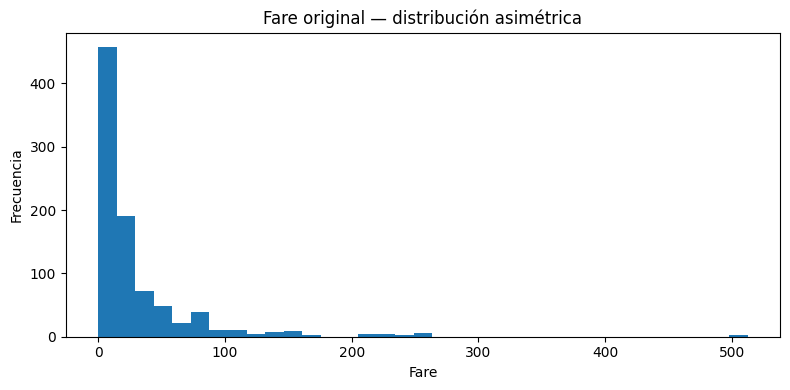

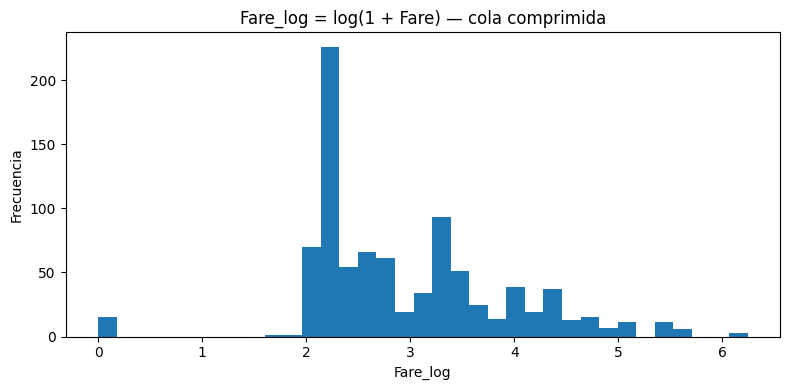

In [ ]:
# 6. Verificación del efecto de la transformación de Fare
comparacion_outliers = pd.concat([
    resumen_outliers_iqr(df_raw.assign(Fare_log=np.log1p(df_raw['Fare'])), ['Fare']),
    resumen_outliers_iqr(df_raw.assign(Fare_log=np.log1p(df_raw['Fare'])), ['Fare_log'])
], ignore_index=True)
display(comparacion_outliers)

plt.figure(figsize=(8, 4))
plt.hist(df_raw['Fare'].dropna(), bins=35)
plt.title('Fare original — distribución asimétrica')
plt.xlabel('Fare')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df_raw['Fare'].dropna()), bins=35)
plt.title('Fare_log = log(1 + Fare) — cola comprimida')
plt.xlabel('Fare_log')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [ ]:
# 7. Estandarización
# Se ajusta sobre X completo para descubrir estructura global sin usar y.
# En un escenario productivo, la estabilidad del clustering debería validarse por remuestreo/tiempo.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

print('Media aproximada tras StandardScaler (primeras variables):')
display(X_scaled_df.mean().to_frame('media').head())
print('Desviación estándar aproximada (ddof=0):')
display(X_scaled_df.std(ddof=0).to_frame('std').head())

Media aproximada tras StandardScaler (primeras variables):


,media
Pclass,-8.772133e-17
Age,2.272780e-16
SibSp,4.386066e-17
Parch,5.382900e-17
HasCabin,-7.376566e-17


Desviación estándar aproximada (ddof=0):


,std
Pclass,1.0
Age,1.0
SibSp,1.0
Parch,1.0
HasCabin,1.0


**Punto 2 — Experimento Con y Sin PCA**

Se comparan dos representaciones:

- **Sin PCA:** conserva las 9 características preprocesadas. Ventaja: mayor interpretabilidad en variables originales. Desventaja: mantiene correlaciones y dimensionalidad completa.
- **Con PCA:** transforma el espacio estandarizado en componentes ortogonales. La selección de `k` se hace **sin usar `y`**, tomando el menor número de componentes cuya varianza explicada acumulada sea al menos **90%**. Según lo visto en clases este valor se sitúa el rango habitual entre 80% y 95%.

PCA puede beneficiar clustering al reducir redundancia y parcialmente la “maldición de la dimensionalidad”, pero puede disminuir interpretabilidad porque cada componente combina variables originales.

In [ ]:
# 8. PCA completo para estudiar varianza explicada
pca_full = PCA()
pca_full.fit(X_scaled)

var_individual = pca_full.explained_variance_ratio_
var_acumulada = np.cumsum(var_individual)

n80 = int(np.argmax(var_acumulada >= 0.80) + 1)
n90 = int(np.argmax(var_acumulada >= 0.90) + 1)

pca_table = pd.DataFrame({
    'Componente': np.arange(1, len(var_individual)+1),
    'Varianza_individual': var_individual,
    'Varianza_acumulada': var_acumulada,
})

display(pca_table)
print(f'Mínimo para >=80%: {n80} componentes')
print(f'Mínimo para >=90%: {n90} componentes')

,Componente,Varianza_individual,Varianza_acumulada
0,1,0.284390,0.284390
1,2,0.199551,0.483941
2,3,0.171431,0.655372
3,4,0.093257,0.748628
4,5,0.082465,0.831094
5,6,0.062136,0.893229
6,7,0.050203,0.943433
7,8,0.035598,0.979031
8,9,0.020969,1.000000


Mínimo para >=80%: 5 componentes
Mínimo para >=90%: 7 componentes


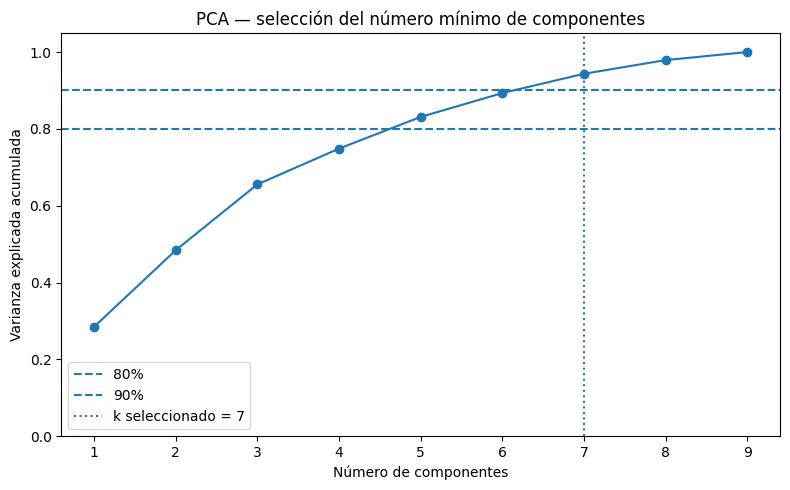

In [ ]:
# 9. Scree plot / varianza explicada acumulada
plt.figure(figsize=(8, 5))
plt.plot(
    pca_table['Componente'],
    pca_table['Varianza_acumulada'],
    marker='o',
)
plt.axhline(0.80, linestyle='--', label='80%')
plt.axhline(0.90, linestyle='--', label='90%')
plt.axvline(n90, linestyle=':', label=f'k seleccionado = {n90}')
plt.xticks(pca_table['Componente'])
plt.ylim(0, 1.05)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA — selección del número mínimo de componentes')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 10. Representación PCA seleccionada formalmente al 90%
pca = PCA(n_components=n90, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print('Sin PCA:', X_scaled.shape)
print('Con PCA:', X_pca.shape)
print(f'Varianza retenida con {n90} componentes: {pca.explained_variance_ratio_.sum()*100:.2f}%')

Sin PCA: (891, 9)
Con PCA: (891, 7)
Varianza retenida con 7 componentes: 94.34%


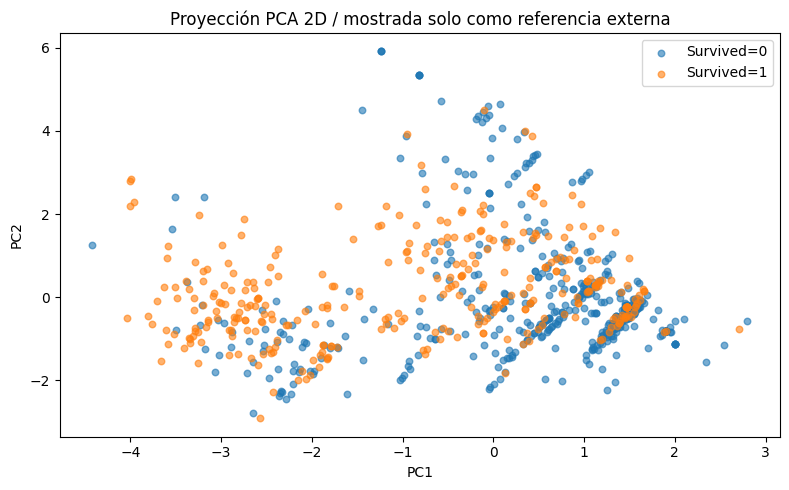

In [ ]:
# 11. Visualización 2D exploratoria de la estructura (PCA 2D)
# y se muestra únicamente como diagnóstico visual, NO para entrenar.
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
for clase in sorted(y.unique()):
    mask = (y.to_numpy() == clase)
    plt.scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        s=22, alpha=0.60, label=f'Survived={clase}'
    )
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Proyección PCA 2D / mostrada solo como referencia externa')
plt.legend()
plt.tight_layout()
plt.show()

**Punto 3 — Challenge entre Algoritmos (Benchmarking)**

Se implementan **6 enfoques** y cada uno se evalúa en las dos representaciones (con y sin PCA):

| Familia | Algoritmo | Idea principal |
|---|---|---|
| Partición / distancia | K-Means | Minimiza suma de distancias cuadradas a centroides. |
| Partición robusta | K-Medoids | Usa observaciones reales como centros y es menos sensible a outliers. |
| Jerárquico / distancia | Agglomerative (Ward) | Fusiona grupos buscando minimizar incremento de varianza intracluster. |
| Distribucional | Gaussian Mixture Model (GMM) | Modela mezcla probabilística de gaussianas. |
| Densidad | DBSCAN | Regiones densas separadas por zonas poco densas; identifica ruido. |
| Densidad | OPTICS | Extiende la lógica de densidad y tolera mejor variaciones de densidad que DBSCAN. |

### Selección de hiperparámetros sin supervisión

- Para K-Means, K-Medoids y Agglomerative se prueba `k = 2...8` y se selecciona el mayor **Silhouette**.
- Para GMM se selecciona el número de componentes con menor **BIC** (criterio probabilístico), y luego se reportan métricas internas comunes.
- Para DBSCAN se exploran `min_samples` y valores de `eps` derivados de cuantiles de la distancia al k-ésimo vecino.
- Para OPTICS se prueban combinaciones acotadas de `min_samples` y `xi`.
- En densidad se utiliza una función de selección `Silhouette - proporción_de_ruido` para impedir que una solución parezca excelente simplemente porque descarta gran parte de los datos como ruido.

> Para Silhouette, Davies–Bouldin y Calinski–Harabasz de DBSCAN/OPTICS se excluyen los puntos `-1` (ruido), pero la **proporción de ruido se reporta por separado**. Esto evita distorsionar las métricas internas y, a la vez, mantiene visible el costo de excluir observaciones.

In [ ]:
# 12. Implementación autocontenida de K-Medoids
# Evita depender de paquetes externos (por ejemplo sklearn-extra) y facilita reproducibilidad.
class KMedoidsSimple:
    """K-Medoids con asignación + actualización del medoid por mínimo costo intracluster."""
    def __init__(self, n_clusters=2, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state

    def fit_predict(self, X_data):
        X_arr = np.asarray(X_data)
        n = len(X_arr)
        rng = np.random.default_rng(self.random_state)
        D = pairwise_distances(X_arr, metric='euclidean')

        # Inicialización farthest-first desde un punto aleatorio
        medoids = [int(rng.integers(n))]
        for _ in range(1, self.n_clusters):
            dmin = np.min(D[:, medoids], axis=1)
            dmin[medoids] = -np.inf
            medoids.append(int(np.argmax(dmin)))
        medoids = np.array(medoids, dtype=int)

        for _ in range(self.max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            nuevos = medoids.copy()

            for c in range(self.n_clusters):
                idx = np.where(labels == c)[0]
                if len(idx) == 0:
                    dmin = np.min(D[:, nuevos], axis=1)
                    dmin[nuevos] = -np.inf
                    nuevos[c] = int(np.argmax(dmin))
                    continue

                subD = D[np.ix_(idx, idx)]
                costos = subD.sum(axis=1)
                nuevos[c] = idx[int(np.argmin(costos))]

            if np.array_equal(nuevos, medoids):
                break
            medoids = nuevos

        self.medoid_indices_ = medoids
        self.labels_ = np.argmin(D[:, medoids], axis=1)
        return self.labels_

In [ ]:
# 13. Funciones de evaluación de modelos de clustering (métricas internas y externas)
def metricas_internas(X_rep, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    labels_validos = labels[mask]
    X_valid = np.asarray(X_rep)[mask]

    n_clusters = len(np.unique(labels_validos)) if len(labels_validos) else 0
    ruido_pct = 100 * np.mean(labels == -1)

    if n_clusters < 2 or len(X_valid) <= n_clusters:
        return {
            'Silhouette': np.nan,
            'Davies_Bouldin': np.nan,
            'Calinski_Harabasz': np.nan,
            'Clusters': n_clusters,
            'Ruido_%': ruido_pct,
        }

    return {
        'Silhouette': silhouette_score(X_valid, labels_validos),
        'Davies_Bouldin': davies_bouldin_score(X_valid, labels_validos),
        'Calinski_Harabasz': calinski_harabasz_score(X_valid, labels_validos),
        'Clusters': n_clusters,
        'Ruido_%': ruido_pct,
    }


def metricas_externas(y_true, labels):
    # Se calculan sobre todas las observaciones; -1 se considera una etiqueta de cluster adicional.
    return {
        'ARI': adjusted_rand_score(y_true, labels),
        'NMI': normalized_mutual_info_score(y_true, labels),
    }

In [ ]:
# 14. Búsqueda para algoritmos con número de clusters k
def buscar_k(X_rep, algoritmo, k_values=range(2, 9)):
    candidatos = []

    for k in k_values:
        if algoritmo == 'K-Means':
            labels = KMeans(
                n_clusters=k,
                n_init=20,
                random_state=RANDOM_STATE,
            ).fit_predict(X_rep)

        elif algoritmo == 'K-Medoids':
            labels = KMedoidsSimple(
                n_clusters=k,
                max_iter=60,
                random_state=RANDOM_STATE,
            ).fit_predict(X_rep)

        elif algoritmo == 'Agglomerative':
            labels = AgglomerativeClustering(
                n_clusters=k,
                linkage='ward',
            ).fit_predict(X_rep)

        else:
            raise ValueError('Algoritmo no soportado')

        m = metricas_internas(X_rep, labels)
        candidatos.append({'k': k, 'labels': labels, **m})

    tabla = pd.DataFrame([{k:v for k,v in c.items() if k!='labels'} for c in candidatos])
    mejor = max(candidatos, key=lambda z: -np.inf if pd.isna(z['Silhouette']) else z['Silhouette'])
    return mejor, tabla


def buscar_gmm(X_rep, k_values=range(2, 9)):
    candidatos = []
    for k in k_values:
        model = GaussianMixture(
            n_components=k,
            covariance_type='full',
            n_init=3,
            reg_covar=1e-6,
            random_state=RANDOM_STATE,
        )
        model.fit(X_rep)
        labels = model.predict(X_rep)
        m = metricas_internas(X_rep, labels)
        candidatos.append({
            'k': k,
            'BIC': model.bic(X_rep),
            'labels': labels,
            **m,
        })

    tabla = pd.DataFrame([{k:v for k,v in c.items() if k!='labels'} for c in candidatos])
    mejor = min(candidatos, key=lambda z: z['BIC'])
    return mejor, tabla

In [ ]:
# 15. Búsqueda DBSCAN basada en k-distances #
def buscar_dbscan(X_rep):
    candidatos = []
    min_samples_grid = [5, 10, 15, 20, 30]
    quantiles = [0.75, 0.80, 0.85, 0.90, 0.95, 0.98]

    for min_samples in min_samples_grid:
        vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_rep)
        distancias, _ = vecinos.kneighbors(X_rep)
        kdist = distancias[:, -1]

        for q in quantiles:
            eps = float(np.quantile(kdist, q))
            labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_rep)
            m = metricas_internas(X_rep, labels)

            # Evitar fragmentaciones extremas para este tamaño de dataset.
            if 2 <= m['Clusters'] <= 10 and not pd.isna(m['Silhouette']):
                score = m['Silhouette'] - (m['Ruido_%'] / 100)
                candidatos.append({
                    'eps': eps,
                    'min_samples': min_samples,
                    'Score_ajustado': score,
                    'labels': labels,
                    **m,
                })

    if not candidatos:
        raise RuntimeError('DBSCAN no produjo configuraciones válidas en la grilla.')

    mejor = max(candidatos, key=lambda z: z['Score_ajustado'])
    tabla = pd.DataFrame([{k:v for k,v in c.items() if k!='labels'} for c in candidatos])
    return mejor, tabla


def buscar_optics(X_rep):
    candidatos = []
    for min_samples in [10, 20, 30]:
        for xi in [0.05, 0.10, 0.15]:
            labels = OPTICS(
                min_samples=min_samples,
                xi=xi,
                min_cluster_size=0.05,
                cluster_method='xi',
            ).fit_predict(X_rep)
            m = metricas_internas(X_rep, labels)

            if 2 <= m['Clusters'] <= 10 and not pd.isna(m['Silhouette']):
                score = m['Silhouette'] - (m['Ruido_%'] / 100)
                candidatos.append({
                    'min_samples': min_samples,
                    'xi': xi,
                    'Score_ajustado': score,
                    'labels': labels,
                    **m,
                })

    if not candidatos:
        raise RuntimeError('OPTICS no produjo configuraciones válidas en la grilla.')

    mejor = max(candidatos, key=lambda z: z['Score_ajustado'])
    tabla = pd.DataFrame([{k:v for k,v in c.items() if k!='labels'} for c in candidatos])
    return mejor, tabla

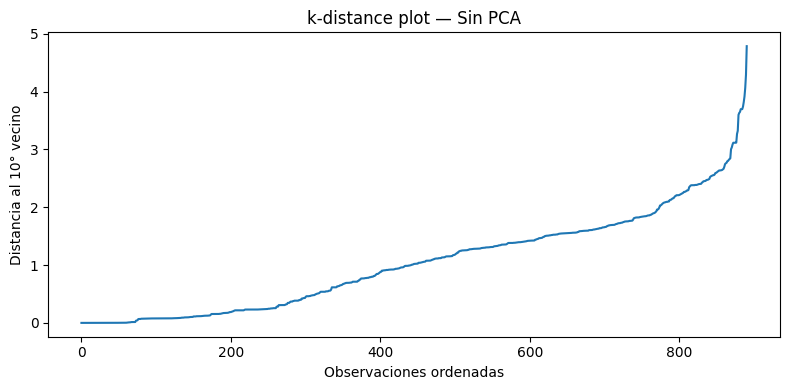

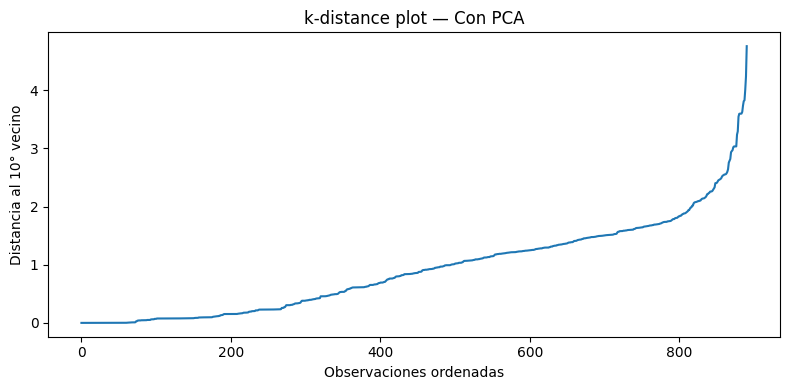

In [ ]:
# 16. Curvas de k-distances para DBSCAN
for nombre_rep, X_rep in {'Sin PCA': X_scaled, 'Con PCA': X_pca}.items():
    k_vecinos = 10
    nn = NearestNeighbors(n_neighbors=k_vecinos).fit(X_rep)
    distancias, _ = nn.kneighbors(X_rep)
    kdist = np.sort(distancias[:, -1])

    plt.figure(figsize=(8, 4))
    plt.plot(kdist)
    plt.xlabel('Observaciones ordenadas')
    plt.ylabel(f'Distancia al {k_vecinos}° vecino')
    plt.title(f'k-distance plot — {nombre_rep}')
    plt.tight_layout()
    plt.show()

In [ ]:
# 17. Benchmark completo en las dos representaciones
representaciones = {
    'Sin PCA': X_scaled,
    'Con PCA': X_pca,
}

resultados = []
labels_guardados = {}
diagnosticos = {}

for nombre_rep, X_rep in representaciones.items():
    print(f'\n=== {nombre_rep} ===')

    # K-Means, K-Medoids y Agglomerative
    for algoritmo in ['K-Means', 'K-Medoids', 'Agglomerative']:
        mejor, tabla = buscar_k(X_rep, algoritmo)
        diagnosticos[(nombre_rep, algoritmo)] = tabla
        labels = mejor['labels']
        labels_guardados[(nombre_rep, algoritmo)] = labels
        resultados.append({
            'Representación': nombre_rep,
            'Modelo': algoritmo,
            'Parámetros': f"k={mejor['k']}",
            **{k:v for k,v in mejor.items() if k not in ['k','labels']},
            **metricas_externas(y, labels),
        })

    # GMM
    mejor, tabla = buscar_gmm(X_rep)
    diagnosticos[(nombre_rep, 'GMM')] = tabla
    labels = mejor['labels']
    labels_guardados[(nombre_rep, 'GMM')] = labels
    resultados.append({
        'Representación': nombre_rep,
        'Modelo': 'GMM',
        'Parámetros': f"n_components={mejor['k']}; BIC={mejor['BIC']:.2f}",
        **{k:v for k,v in mejor.items() if k not in ['k','BIC','labels']},
        **metricas_externas(y, labels),
    })

    # DBSCAN
    mejor, tabla = buscar_dbscan(X_rep)
    diagnosticos[(nombre_rep, 'DBSCAN')] = tabla
    labels = mejor['labels']
    labels_guardados[(nombre_rep, 'DBSCAN')] = labels
    resultados.append({
        'Representación': nombre_rep,
        'Modelo': 'DBSCAN',
        'Parámetros': f"eps={mejor['eps']:.3f}; min_samples={mejor['min_samples']}",
        **{k:v for k,v in mejor.items() if k not in ['eps','min_samples','labels','Score_ajustado']},
        **metricas_externas(y, labels),
    })

    # OPTICS
    mejor, tabla = buscar_optics(X_rep)
    diagnosticos[(nombre_rep, 'OPTICS')] = tabla
    labels = mejor['labels']
    labels_guardados[(nombre_rep, 'OPTICS')] = labels
    resultados.append({
        'Representación': nombre_rep,
        'Modelo': 'OPTICS',
        'Parámetros': f"min_samples={mejor['min_samples']}; xi={mejor['xi']}",
        **{k:v for k,v in mejor.items() if k not in ['min_samples','xi','labels','Score_ajustado']},
        **metricas_externas(y, labels),
    })

benchmark = pd.DataFrame(resultados)

# Orden de columnas
benchmark = benchmark[[
    'Representación','Modelo','Parámetros','Clusters','Ruido_%',
    'Silhouette','Davies_Bouldin','Calinski_Harabasz','ARI','NMI'
]]

display(benchmark.round(4))


=== Sin PCA ===

=== Con PCA ===


,Representación,Modelo,Parámetros,Clusters,Ruido_%,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI
0,Sin PCA,K-Means,k=4,4,0.0000,0.3606,1.2511,282.1306,0.1369,0.0765
1,Sin PCA,K-Medoids,k=8,8,0.0000,0.3140,1.3291,201.5251,0.1687,0.1326
2,Sin PCA,Agglomerative,k=4,4,0.0000,0.3632,1.1490,252.3731,0.0980,0.0681
3,Sin PCA,GMM,n_components=6; BIC=-22216.39,6,0.0000,0.2530,1.9884,161.0743,0.1121,0.0868
4,Sin PCA,DBSCAN,eps=3.120; min_samples=30,2,0.8979,0.3346,1.0067,162.2824,-0.0040,0.0088
5,Sin PCA,OPTICS,min_samples=10; xi=0.05,8,37.7104,0.4072,0.9147,237.8885,0.0120,0.0696
6,Con PCA,K-Means,k=4,4,0.0000,0.3812,1.1962,315.4588,0.1342,0.0749
7,Con PCA,K-Medoids,k=8,8,0.0000,0.3474,1.2315,243.6028,0.1836,0.1453
8,Con PCA,Agglomerative,k=4,4,0.0000,0.3931,1.0586,287.4064,0.1013,0.0742
9,Con PCA,GMM,n_components=8; BIC=-6373.06,8,0.0000,0.2977,1.6290,161.3276,0.1543,0.1481


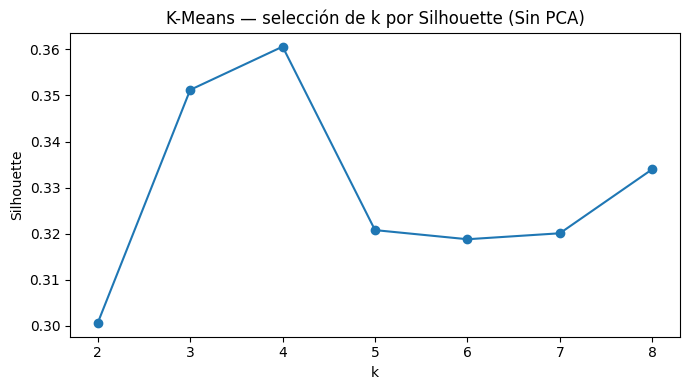

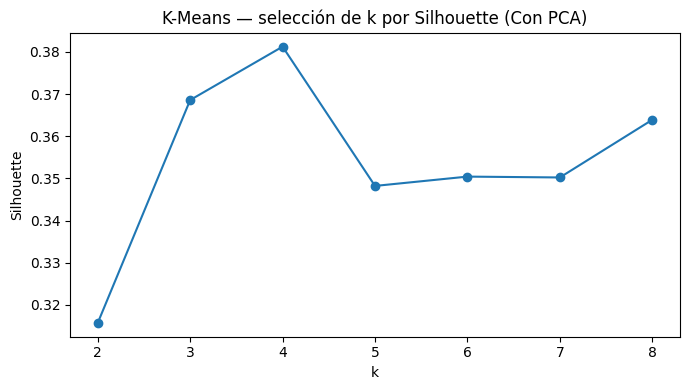

In [ ]:
# 18. Diagnóstico de k para K-Means
for nombre_rep in representaciones:
    tabla = diagnosticos[(nombre_rep, 'K-Means')]
    plt.figure(figsize=(7, 4))
    plt.plot(tabla['k'], tabla['Silhouette'], marker='o')
    plt.xlabel('k')
    plt.ylabel('Silhouette')
    plt.title(f'K-Means — selección de k por Silhouette ({nombre_rep})')
    plt.xticks(tabla['k'])
    plt.tight_layout()
    plt.show()

**Punto 4 — Evaluación y Selección del Modelo**

Métricas internas utilizadas

- **Silhouette Score:** combina cohesión y separación. Más alto es mejor; valores próximos a `+1` indican clusters bien separados.
- **Davies–Bouldin Index:** compara dispersión interna y separación entre clusters. **Más bajo es mejor**.
- **Calinski–Harabasz Score:** razón entre variabilidad entre clusters y dentro de clusters. **Más alto es mejor**.

Estas tres métricas aparecen explícitamente en U3 como criterios de validación interna. Ninguna debe interpretarse de manera aislada: Silhouette y Davies–Bouldin pueden favorecer estructuras compactas, mientras que Calinski–Harabasz suele ser especialmente informativo para clusters aproximadamente convexos/esféricos.

Regla de selección

La selección se hace **sin ARI/NMI**. Primero se descartan soluciones de densidad con más de **35% de ruido**, porque una Silhouette alta calculada sobre una fracción pequeña del dataset puede ser engañosa. Luego se calcula un **ranking promedio** entre Silhouette (descendente), Davies–Bouldin (ascendente) y Calinski–Harabasz (descendente). En caso de empate se favorece menor ruido y menor complejidad.

In [ ]:
# 19. Selección interna formal, sin usar y
seleccion = benchmark.copy()

# Elegibilidad: métricas válidas y ruido razonable.
seleccion['Elegible'] = (
    seleccion['Silhouette'].notna()
    & seleccion['Davies_Bouldin'].notna()
    & seleccion['Calinski_Harabasz'].notna()
    & (seleccion['Ruido_%'] <= 35)
)

elegibles = seleccion[seleccion['Elegible']].copy()

if elegibles.empty:
    raise RuntimeError('No quedaron configuraciones elegibles para selección interna.')

elegibles['Rank_Silhouette'] = elegibles['Silhouette'].rank(ascending=False, method='min')
elegibles['Rank_Davies'] = elegibles['Davies_Bouldin'].rank(ascending=True, method='min')
elegibles['Rank_Calinski'] = elegibles['Calinski_Harabasz'].rank(ascending=False, method='min')
elegibles['Rank_Promedio'] = elegibles[[
    'Rank_Silhouette','Rank_Davies','Rank_Calinski'
]].mean(axis=1)

# Desempate: menos ruido, luego menos clusters (interpretabilidad)
elegibles = elegibles.sort_values(
    ['Rank_Promedio','Ruido_%','Clusters'],
    ascending=[True, True, True]
).reset_index(drop=True)

mejor_fila = elegibles.iloc[0]
mejor_clave = (mejor_fila['Representación'], mejor_fila['Modelo'])
mejor_labels = labels_guardados[mejor_clave]

print('Ranking interno de modelos elegibles:')
display(elegibles[[
    'Representación','Modelo','Parámetros','Clusters','Ruido_%',
    'Silhouette','Davies_Bouldin','Calinski_Harabasz','Rank_Promedio'
]].round(4))

print('\nMODELO SELECCIONADO SOLO CON MÉTRICAS INTERNAS:')
print(mejor_fila[['Representación','Modelo','Parámetros','Clusters','Ruido_%',
                 'Silhouette','Davies_Bouldin','Calinski_Harabasz']])

Ranking interno de modelos elegibles:


,Representación,Modelo,Parámetros,Clusters,Ruido_%,Silhouette,Davies_Bouldin,Calinski_Harabasz,Rank_Promedio
0,Con PCA,Agglomerative,k=4,4,0.0000,0.3931,1.0586,287.4064,2.0000
1,Con PCA,K-Means,k=4,4,0.0000,0.3812,1.1962,315.4588,2.6667
2,Sin PCA,Agglomerative,k=4,4,0.0000,0.3632,1.1490,252.3731,3.6667
3,Con PCA,DBSCAN,eps=2.961; min_samples=30,2,1.0101,0.3558,0.9748,173.8943,4.3333
4,Sin PCA,K-Means,k=4,4,0.0000,0.3606,1.2511,282.1306,4.6667
5,Con PCA,K-Medoids,k=8,8,0.0000,0.3474,1.2315,243.6028,5.6667
6,Sin PCA,DBSCAN,eps=3.120; min_samples=30,2,0.8979,0.3346,1.0067,162.2824,5.6667
7,Sin PCA,K-Medoids,k=8,8,0.0000,0.3140,1.3291,201.5251,7.3333
8,Con PCA,GMM,n_components=8; BIC=-6373.06,8,0.0000,0.2977,1.6290,161.3276,9.0000
9,Sin PCA,GMM,n_components=6; BIC=-22216.39,6,0.0000,0.2530,1.9884,161.0743,10.0000



MODELO SELECCIONADO SOLO CON MÉTRICAS INTERNAS:
Representación             Con PCA
Modelo               Agglomerative
Parámetros                     k=4
Clusters                         4
Ruido_%                        0.0
Silhouette                0.393058
Davies_Bouldin            1.058568
Calinski_Harabasz       287.406397
Name: 0, dtype: object


## Validación externa con `y = Survived`

Una vez seleccionado el modelo por criterios internos, se compara el clustering con `Survived` mediante:

- **Adjusted Rand Index (ARI):** mide concordancia entre dos particiones corrigiendo el acuerdo esperado por azar. Valores cercanos a 1 indican alta coincidencia; cerca de 0, coincidencia similar al azar.
- **Normalized Mutual Information (NMI):** mide información compartida entre las etiquetas de clusters y la etiqueta externa, normalizada entre 0 y 1.
- **Matriz de contingencia:** muestra cómo se distribuyen sobrevivientes y no sobrevivientes dentro de cada cluster.

Importante: un ARI/NMI bajo **no significa automáticamente que el clustering sea incorrecto**. Puede significar que la estructura natural del espacio de características responde a más factores que la sola supervivencia. La variable `Survived` es una referencia externa útil, no la función objetivo del clustering.

In [ ]:
# 20. Métricas externas de todos los modelos (solo diagnóstico posterior)
externas = benchmark[[
    'Representación','Modelo','Parámetros','ARI','NMI','Ruido_%'
]].copy()
externas = externas.sort_values(['ARI','NMI'], ascending=False).reset_index(drop=True)
display(externas.round(4))

print('ARI y NMI del modelo elegido internamente:')
print(f"ARI = {adjusted_rand_score(y, mejor_labels):.4f}")
print(f"NMI = {normalized_mutual_info_score(y, mejor_labels):.4f}")

,Representación,Modelo,Parámetros,ARI,NMI,Ruido_%
0,Con PCA,K-Medoids,k=8,0.1836,0.1453,0.0000
1,Sin PCA,K-Medoids,k=8,0.1687,0.1326,0.0000
2,Con PCA,GMM,n_components=8; BIC=-6373.06,0.1543,0.1481,0.0000
3,Sin PCA,K-Means,k=4,0.1369,0.0765,0.0000
4,Con PCA,K-Means,k=4,0.1342,0.0749,0.0000
5,Sin PCA,GMM,n_components=6; BIC=-22216.39,0.1121,0.0868,0.0000
6,Con PCA,Agglomerative,k=4,0.1013,0.0742,0.0000
7,Sin PCA,Agglomerative,k=4,0.0980,0.0681,0.0000
8,Sin PCA,OPTICS,min_samples=10; xi=0.05,0.0120,0.0696,37.7104
9,Con PCA,OPTICS,min_samples=10; xi=0.05,0.0097,0.0831,46.9136


ARI y NMI del modelo elegido internamente:
ARI = 0.1013
NMI = 0.0742


In [ ]:
# 21. Matriz de contingencia del modelo seleccionado
contingencia = pd.crosstab(
    pd.Series(mejor_labels, name='Cluster'),
    pd.Series(y.to_numpy(), name='Survived'),
    margins=True,
)
print('Conteos:')
display(contingencia)

contingencia_pct = pd.crosstab(
    pd.Series(mejor_labels, name='Cluster'),
    pd.Series(y.to_numpy(), name='Survived'),
    normalize='index',
) * 100
print('Porcentaje dentro de cada cluster:')
display(contingencia_pct.round(2))

Conteos:


Survived,0,1,All
Cluster,,,
0,395,164,559
1,67,142,209
2,46,30,76
3,41,6,47
All,549,342,891


Porcentaje dentro de cada cluster:


Survived,0,1
Cluster,,
0,70.66,29.34
1,32.06,67.94
2,60.53,39.47
3,87.23,12.77


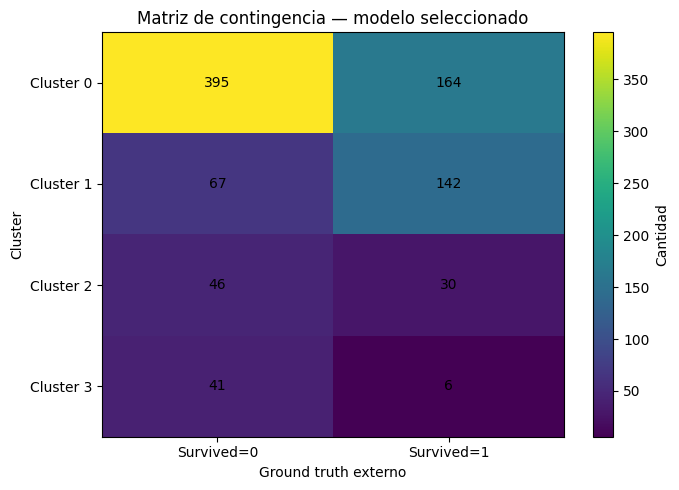

In [ ]:
# 22. Visualización de la matriz de contingencia (sin fila/columna de totales)
mat = pd.crosstab(
    pd.Series(mejor_labels, name='Cluster'),
    pd.Series(y.to_numpy(), name='Survived')
)

plt.figure(figsize=(7, 5))
img = plt.imshow(mat.values, aspect='auto')
plt.colorbar(img, label='Cantidad')
plt.xticks(range(len(mat.columns)), [f'Survived={c}' for c in mat.columns])
plt.yticks(range(len(mat.index)), [f'Cluster {c}' for c in mat.index])
plt.xlabel('Ground truth externo')
plt.ylabel('Cluster')
plt.title('Matriz de contingencia — modelo seleccionado')

for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        plt.text(j, i, str(mat.iloc[i, j]), ha='center', va='center')

plt.tight_layout()
plt.show()

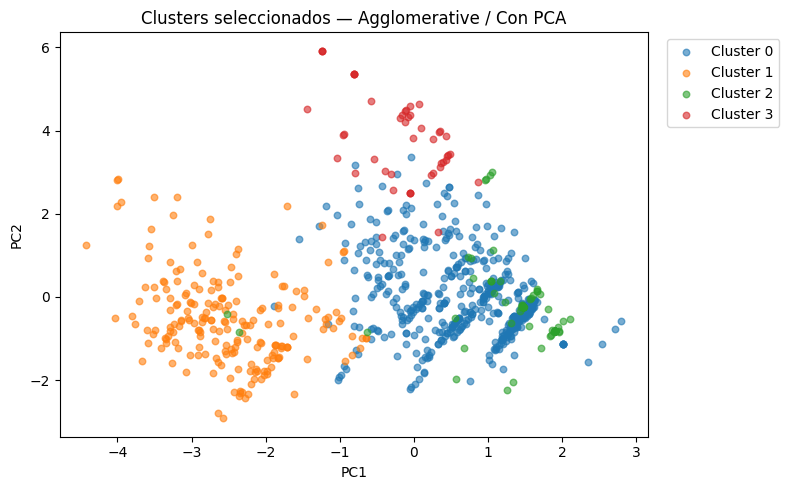

In [ ]:
# 23. Visualización del clustering seleccionado sobre una proyección PCA 2D
plt.figure(figsize=(8, 5))
for cluster in np.unique(mejor_labels):
    mask = mejor_labels == cluster
    etiqueta = 'Ruido (-1)' if cluster == -1 else f'Cluster {cluster}'
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=22, alpha=0.60, label=etiqueta)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(
    f"Clusters seleccionados — {mejor_fila['Modelo']} / {mejor_fila['Representación']}"
)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 24. Perfil interpretativo de los clusters en variables originales
perfil = df_raw.drop_duplicates().reset_index(drop=True).copy()
perfil['HasCabin'] = perfil['Cabin'].notna().astype(int)
perfil['Age'] = perfil['Age'].fillna(perfil['Age'].median())
perfil['Fare'] = perfil['Fare'].fillna(perfil['Fare'].median())
perfil['Cluster'] = mejor_labels
perfil['Survived_ref'] = y.to_numpy()

perfil_numerico = perfil.groupby('Cluster').agg(
    n=('Cluster','size'),
    Pclass_media=('Pclass','mean'),
    Edad_media=('Age','mean'),
    Fare_medio=('Fare','mean'),
    SibSp_media=('SibSp','mean'),
    Parch_media=('Parch','mean'),
    Cabin_disponible_pct=('HasCabin', lambda s: 100*s.mean()),
    Supervivencia_pct_solo_diagnostico=('Survived_ref', lambda s: 100*s.mean()),
)

display(perfil_numerico.round(2))

print('Distribución de sexo por cluster (%):')
display((pd.crosstab(perfil['Cluster'], perfil['Sex'], normalize='index')*100).round(2))

print('Distribución de puerto de embarque por cluster (%):')
display((pd.crosstab(perfil['Cluster'], perfil['Embarked'], normalize='index')*100).round(2))

,n,Pclass_media,Edad_media,Fare_medio,SibSp_media,Parch_media,Cabin_disponible_pct,Supervivencia_pct_solo_diagnostico
Cluster,,,,,,,,
0,559,2.63,28.07,14.70,0.29,0.26,2.68,29.34
1,209,1.08,35.70,84.84,0.44,0.40,88.52,67.94
2,76,2.91,27.89,13.07,0.43,0.11,5.26,39.47
3,47,2.98,18.96,37.29,3.81,2.21,0.00,12.77


Distribución de sexo por cluster (%):


Sex,female,male
Cluster,,
0,26.83,73.17
1,49.28,50.72
2,46.05,53.95
3,55.32,44.68


Distribución de puerto de embarque por cluster (%):


Embarked,C,Q,S
Cluster,,,
0,14.31,0.00,85.69
1,42.51,0.00,57.49
2,0.00,100.00,0.00
3,0.00,2.13,97.87


In [ ]:
# 25. Resumen automático para la conclusión
ari_best = adjusted_rand_score(y, mejor_labels)
nmi_best = normalized_mutual_info_score(y, mejor_labels)

print('RESUMEN EJECUTIVO DEL EXPERIMENTO')
print('-' * 55)
print(f'Variables originales usadas en clustering: {X.shape[1]}')
print(f'Componentes PCA seleccionados: {n90}')
print(f'Varianza retenida PCA: {pca.explained_variance_ratio_.sum()*100:.2f}%')
print(f'Mejor representación: {mejor_fila["Representación"]}')
print(f'Mejor algoritmo interno: {mejor_fila["Modelo"]}')
print(f'Parámetros: {mejor_fila["Parámetros"]}')
print(f'Silhouette: {mejor_fila["Silhouette"]:.4f}')
print(f'Davies-Bouldin: {mejor_fila["Davies_Bouldin"]:.4f}')
print(f'Calinski-Harabasz: {mejor_fila["Calinski_Harabasz"]:.4f}')
print(f'Ruido: {mejor_fila["Ruido_%"]:.2f}%')
print(f'ARI vs Survived: {ari_best:.4f}')
print(f'NMI vs Survived: {nmi_best:.4f}')

RESUMEN EJECUTIVO DEL EXPERIMENTO
-------------------------------------------------------
Variables originales usadas en clustering: 9
Componentes PCA seleccionados: 7
Varianza retenida PCA: 94.34%
Mejor representación: Con PCA
Mejor algoritmo interno: Agglomerative
Parámetros: k=4
Silhouette: 0.3931
Davies-Bouldin: 1.0586
Calinski-Harabasz: 287.4064
Ruido: 0.00%
ARI vs Survived: 0.1013
NMI vs Survived: 0.0742


## Interpretación metodológica del resultado

La elección final debe leerse en dos niveles:

1. **Calidad intrínseca del clustering:** el ranking interno resume cohesión/separación mediante Silhouette, Davies–Bouldin y Calinski–Harabasz. Esta es la base formal de selección porque el problema es no supervisado.
2. **Correspondencia con el fenómeno conocido:** ARI, NMI y la contingencia indican cuánto coincide la segmentación con `Survived`. Si la concordancia es limitada, la conclusión correcta no es “el modelo falló”, sino que la geometría del dataset puede estar capturando perfiles de pasajeros (clase, edad, tarifa, acompañantes, cabina, sexo, puerto) que no se reducen a una división binaria idéntica a supervivencia.

También debe observarse el efecto de PCA: si la variante con PCA mejora las métricas internas, hay evidencia de que eliminar redundancia favoreció la estructura geométrica; si no mejora, la información útil para separar grupos estaba mejor preservada en el espacio original. Esta comparación constituye precisamente el experimento solicitado por la pauta.

# **Conclusión**

Este trabajo extiende de forma coherente las Unidades 1 y 2 hacia aprendizaje no supervisado. El pipeline conserva las decisiones de calidad de datos previas, evita fuga de información desde `Survived`, estandariza el espacio antes de usar distancias y compara formalmente una representación completa con otra reducida por PCA.

El *benchmark* no asume que exista un único tipo de estructura: contrasta particiones centroidales, medoids, jerarquía, mezcla probabilística y densidad. La selección se fundamenta en varias métricas internas y controla explícitamente la proporción de ruido en modelos de densidad. Finalmente, ARI, NMI y la matriz de contingencia permiten comprobar si los clusters descubiertos corresponden a la variable objetivo de las unidades anteriores, sin haberla usado para construirlos.

Como mejora futura se podría evaluar **estabilidad de clusters por bootstrap**, **HDBSCAN/DBCV**, distancia de **Gower** para datos mixtos, o métodos no lineales de representación.